**Human Movement Intelligence | Gait Analysis | Presented by: Reza Saadatyar (2026)**

**02 | Alignment and Event Reference**

![Alignment and Event Reference](../../images/02_alignment_and_event_reference.svg)

**Objective:** Review original source-channel conventions and time coordinates before constructing independent force-derived initial-contact (IC) and terminal-contact (TC) references. Once the physical reference contract is defensible, prepare participant-disjoint evaluation inputs.

**Current evidence:** The completed Notebook 01 source audit contains **nine source-paired participants (AB06–AB14)** and **27 treadmill IMU/force pairs** with overlapping native `Header` intervals. This confirms source availability and timestamp readability, **not** force-contact reference validity.

**Notebook scope:** Source-contract audit, diagnostic figure, conditional force-event extraction, eligibility/exclusion tables, participant-disjoint roles and downloadable outputs. Until the independent physical contract is verified, downstream stages are clearly deferred rather than assigned artificial results.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
# This IPython-native checkout requires no imports outside Section 01.
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = "/content/human-movement-intelligence"
shell = get_ipython()
if shell is None:
    raise RuntimeError("Execute this notebook in Google Colab or IPython.")
shell.system(
    f'if [ ! -d "{repo_path}" ]; then git clone -q "{repo_url}" '
    f'"{repo_path}"; fi'
)

# ---------------------------- 2. Open Repository -----------------------------
shell.run_line_magic("cd", repo_path)


/content/human-movement-intelligence


**01. Imports and Research Environment**

Use the established shared utilities and Camargo-specific alignment/reference functions. If a dirty existing Colab checkout defers a Git fast-forward, Section 01 can retrieve only the missing source-contract module into an isolated runtime directory without altering tracked files or original data. This recovery is not a complete Git synchronisation. No source dataset download or model training is triggered by these imports.


In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
from pathlib import Path
import subprocess
root = setup_colab("gait_analysis")
NOTEBOOK_NUMBER = 2

# ----------------------- 2. MATLAB Table Reader Setup ------------------------
import importlib
import importlib.util
import sys

if importlib.util.find_spec("matio") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "mat-io==1.0.2"],
        check=True,
    )

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import os
import re
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# ------------------------ 5. Study Research Utilities ------------------------
from camargo_source import read_sensor_table, validate_timebase
from gait_alignment import mapped_series, validated_overlap
from gait_reference import force_contact_events
from gait_experiments import save_prepared_trial, read_prepared_trial
from gait_evaluation import participant_roles, development_folds

# ---------------- 5A. Non-Destructive Missing-Module Recovery ----------------
# A dirty Colab checkout can defer its Git fast-forward. Never discard
# local notebook outputs or original Camargo recordings to resolve imports.
# Only if this module is absent, fetch its public source into a separate
# temporary runtime directory; the local Git checkout is not modified.
if importlib.util.find_spec("gait_contract_evidence") is None:
    remote_relative = "gait_analysis/code/src/gait_contract_evidence.py"
    runtime_modules = root.parent / ".hmi_gait_runtime_modules"
    runtime_modules.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["git", "fetch", "--no-tags", "origin", "main"],
        cwd=root, check=True, capture_output=True, text=True,
    )
    fetched_module = subprocess.run(
        ["git", "show", f"FETCH_HEAD:{remote_relative}"],
        cwd=root, check=True, capture_output=True,
    )
    runtime_module = runtime_modules / "gait_contract_evidence.py"
    runtime_module.write_bytes(fetched_module.stdout)
    if str(runtime_modules) not in sys.path:
        sys.path.insert(0, str(runtime_modules))
    importlib.invalidate_caches()
    print(
        "Missing Gait module recovered from origin/main into a separate "
        "runtime directory. Local source files and outputs were preserved; "
        "the Git checkout was NOT fast-forwarded."
    )

from gait_contract_evidence import (
    audit_candidate_pairs, plot_source_contract_probe,
    validate_explicit_contract,
)

# ---------------------- 6. Source and Output Locations -----------------------
study_dir = root / "gait_analysis"
source_root = Path(os.environ.get("CAMARGO_DATA_ROOT",
                                  root / "data/raw/camargo"))
output_dir = study_dir / "output"
cache_dir = root / "data/processed/camargo/paired_trials"
output_dir.mkdir(parents=True, exist_ok=True)


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Missing Gait module recovered from origin/main into a separate runtime directory. Local source files and outputs were preserved; the Git checkout was NOT fast-forwarded.


**02. Audit Original Sensor Columns, Time Coordinates and Force Direction**

Read the current Notebook 01 `01_candidate_pairs.csv` and `01_observed_columns.csv` and use the per-trial `01_trial_timebase_audit.csv` where available. The executed nine-person audit found 27 readable pairs with positive native-time overlap, IMU median `Header` increments of approximately 0.005 and treadmill force increments of approximately 0.001 (source-time units). The force-channel candidates `Treadmill_R_vy` and `Treadmill_L_vy` were present.

The original [Camargo dataset README](https://data.mendeley.com/datasets/fcgm3chfff/1) states that `Header` timestamps are used to synchronise channels and identifies native rates of 200 Hz for IMU and 1,000 Hz for force plates. This supports inspecting time-base compatibility, **not** treating every overlap as an independently validated millisecond-level alignment. The source also supplies right- and left-side gait-cycle annotations (`gcRight`/`gcLeft`), but those derived labels are **not currently used as an alternative primary reference**.

The executed section generated [`02_source_contract_review.csv`](../../output/02_source_contract_review.csv) and a [recorded signal figure](../../output/02_source_contract_diagnostic.png) showing foot/shank IMU channels and right/left treadmill components. The force channels **exist** and show alternating loading-like profiles; no source file is missing. These are descriptive measurements in original source units. Physical vertical-axis mapping, Newton scaling, force polarity, correspondence to the instrumented foot, and common-clock acceptance still require the source contract to be established. The workflow SVG is schematic; the new PNG is the recorded diagnostic.


Source-paired people: 9
Candidate source pairs: 27
Gyroscope fields: ['foot_Gyro_X', 'foot_Gyro_Y', 'foot_Gyro_Z', 'shank_Gyro_X', 'shank_Gyro_Y', 'shank_Gyro_Z', 'thigh_Gyro_X', 'thigh_Gyro_Y', 'thigh_Gyro_Z', 'trunk_Gyro_X', 'trunk_Gyro_Y', 'trunk_Gyro_Z']
Treadmill force fields: ['Treadmill_L_vx', 'Treadmill_L_vy', 'Treadmill_L_vz', 'Treadmill_R_vx', 'Treadmill_R_vy', 'Treadmill_R_vz']


,subject_id,session_id,condition,trial_id,status,imu_start,imu_end,force_start,force_end,imu_median_step,force_median_step,native_overlap,start_difference,end_difference,read_error
0,AB06,10_09_18,treadmill,treadmill_01_01,readable_with_time_overlap,11.990,155.045,11.990,155.045,0.005,0.001,143.055,0.000,0.0,NaN
1,AB06,10_09_18,treadmill,treadmill_04_01,readable_with_time_overlap,12.475,156.035,12.472,156.035,0.005,0.001,143.560,0.003,0.0,NaN
2,AB06,10_09_18,treadmill,treadmill_08_01,readable_with_time_overlap,10.680,154.900,10.678,154.900,0.005,0.001,144.220,0.002,0.0,NaN
3,AB07,10_14_18,treadmill,treadmill_01_01,readable_with_time_overlap,10.360,153.415,10.359,153.415,0.005,0.001,143.055,0.001,0.0,NaN
4,AB07,10_14_18,treadmill,treadmill_04_2_01,readable_with_time_overlap,10.025,153.585,10.021,153.585,0.005,0.001,143.560,0.004,0.0,NaN
5,AB07,10_14_18,treadmill,treadmill_08_01,readable_with_time_overlap,8.795,153.015,8.793,153.015,0.005,0.001,144.220,0.002,0.0,NaN
6,AB08,10_21_2018,treadmill,treadmill_01_01,readable_with_time_overlap,8.630,151.525,8.627,151.525,0.005,0.001,142.895,0.003,0.0,NaN
7,AB08,10_21_2018,treadmill,treadmill_04_01,readable_with_time_overlap,12.085,155.470,12.082,155.470,0.005,0.001,143.385,0.003,0.0,NaN
8,AB08,10_21_2018,treadmill,treadmill_07_01,readable_with_time_overlap,9.575,153.455,9.573,153.455,0.005,0.001,143.880,0.002,0.0,NaN
9,AB09,10_21_2018,treadmill,treadmill_01_01,readable_with_time_overlap,14.020,156.920,14.017,156.920,0.005,0.001,142.900,0.003,0.0,NaN


,setting,candidate,observed,unresolved
0,GYRO_COLUMN,foot_Gyro_Y,True,Verify the selected gyroscope axis and instrum...
1,VERTICAL_FORCE_COLUMN,Treadmill_R_vy,True,"Verify physical vertical axis, source units an..."
2,FOOT_SIDE,right (candidate),<NA>,Confirm physical IMU foot side and force-plate...
3,FORCE_UPWARD_SIGN,positive (candidate),<NA>,Verify the real loading polarity and swing-pha...
4,TIME_UNIT_IN_SECONDS,1.0 (candidate),<NA>,Confirm Header time units with original 200/10...
5,IMU_FORCE_TIMEBASE_CONFIRMED,not confirmed,<NA>,Confirm a common event-level clock for retaine...
6,FORCE_SCALE_TO_NEWTONS,not confirmed,<NA>,Confirm conversion from original force units t...


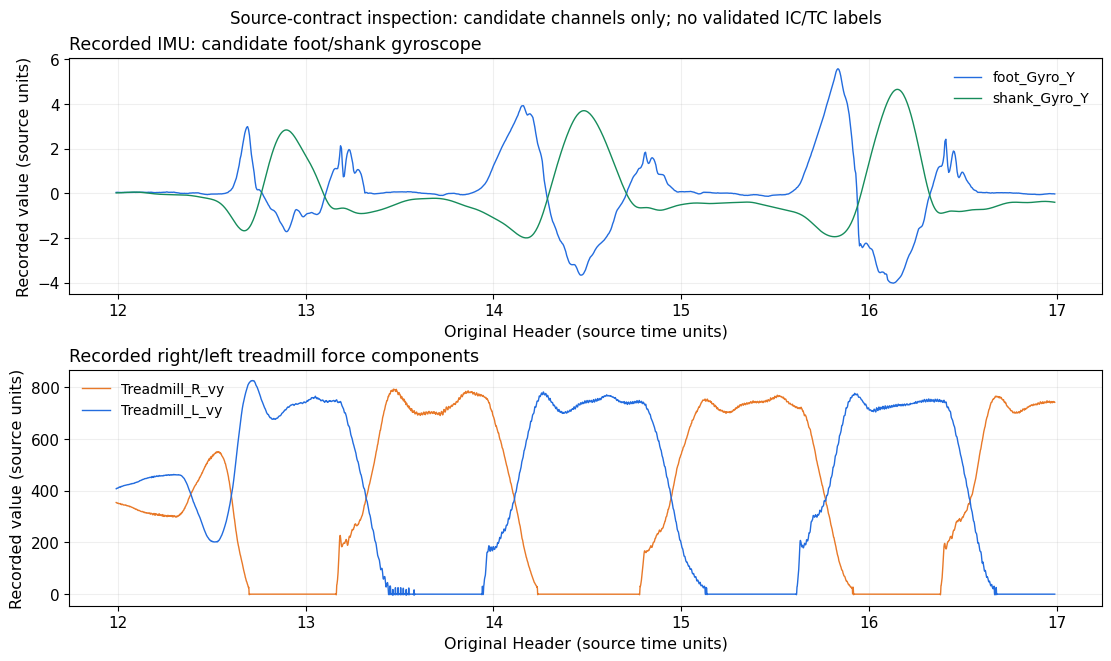

Original recorded diagnostic: AB06 treadmill_01_01
Native timestamp start difference: 0.0
Native timestamp end difference: 0.0
Descriptive source inspection complete. Contact-event extraction is still blocked pending physical channel and timebase verification.
Evidence saved to: /content/human-movement-intelligence/gait_analysis/output/02_source_contract_review.csv


In [3]:
# ==================== 02. Review Original Sensor Contract ====================

# ------------- 1. Load Recorded Source Pair and Channel Evidence -------------
pair_file = output_dir / "01_candidate_pairs.csv"
column_file = output_dir / "01_observed_columns.csv"
timebase_file = output_dir / "01_trial_timebase_audit.csv"
if not pair_file.is_file() or not column_file.is_file():
    raise FileNotFoundError(
        "Notebook 01's candidate pairs and observed columns are missing. "
        "Run Notebook 01 Sections 03–07 before inspecting references."
    )
pairs = pd.read_csv(pair_file)
pairs = pairs.loc[
    pairs.candidate_pair & pairs.condition.eq("treadmill")
].copy()
observed = pd.read_csv(column_file)
if pairs.empty:
    raise ValueError("No source-matched treadmill IMU/force trial pairs.")
imu_names = set(observed.loc[observed.modality == "imu", "column"])
fp_names = set(observed.loc[observed.modality == "fp", "column"])
if timebase_file.is_file():
    timebase_audit = pd.read_csv(timebase_file)
    if len(timebase_audit) != len(pairs):
        print("Trial-level timestamp audit is incomplete; rerun "
              "Notebook 01 Sections 05–07 to refresh the evidence.")
else:
    timebase_audit = pd.DataFrame()
    print("Trial-level timestamp audit missing. Rerun updated "
          "Notebook 01 Section 05 before reference extraction.")
print("Source-paired people:", pairs.subject_id.nunique())
print("Candidate source pairs:", len(pairs))
print("Gyroscope fields:", sorted(
    name for name in imu_names if "Gyro" in name
))
print("Treadmill force fields:", sorted(
    name for name in fp_names
    if "Treadmill_" in name and "_v" in name
))
if not timebase_audit.empty:
    display(timebase_audit)


# ------------------- 2. Save Scientific Contract Evidence --------------------
contract_review = pd.DataFrame([
    {"setting": "GYRO_COLUMN", "candidate": "foot_Gyro_Y",
     "observed": "foot_Gyro_Y" in imu_names,
     "unresolved": "Fixed observed model-input axis; do not claim anatomical orientation or Test-derived selection."},
    {"setting": "VERTICAL_FORCE_COLUMN",
     "candidate": "Treadmill_R_vy",
     "observed": "Treadmill_R_vy" in fp_names,
     "unresolved": "Verify physical vertical axis, source units and belt side."},
    {"setting": "FOOT_SIDE", "candidate": "right (author-reported)",
     "observed": pd.NA,
     "unresolved": "Right-sided wearable IMU in Camargo et al. (2021); verify R/L treadmill belt correspondence."},
    {"setting": "FORCE_UPWARD_SIGN", "candidate": "positive (candidate)",
     "observed": pd.NA,
     "unresolved": "Verify the real loading polarity and swing-phase baseline."},
    {"setting": "TIME_UNIT_IN_SECONDS",
     "candidate": "1.0 (seconds in source paper)",
     "observed": pd.NA,
     "unresolved": "Header time in seconds reported by Camargo et al. (2021); native 200/1000-Hz steps observed."},
    {"setting": "IMU_FORCE_TIMEBASE_CONFIRMED",
     "candidate": "not confirmed", "observed": pd.NA,
     "unresolved": "Confirm a common event-level clock for retained trials."},
    {"setting": "FORCE_SCALE_TO_NEWTONS", "candidate": "not confirmed",
     "observed": pd.NA,
     "unresolved": "Confirm conversion from original force units to newtons."},
])
display(contract_review)
contract_review.to_csv(
    output_dir / "02_source_contract_review.csv", index=False
)


# ------------- 3. Inspect Recorded Right-Left Treadmill Signals --------------
sample = pairs.iloc[0]
imu_path = source_root / sample.imu_path
fp_path = source_root / sample.fp_path
if imu_path.is_file() and fp_path.is_file():
    inspect_imu = read_sensor_table(imu_path)
    inspect_fp = read_sensor_table(fp_path)
    time_imu = validate_timebase(inspect_imu, "IMU")
    time_fp = validate_timebase(inspect_fp, "force")
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6.5), layout="constrained"
    )
    trial_window_imu = time_imu <= time_imu[0] + 5.0
    trial_window_fp = time_fp <= time_fp[0] + 5.0
    for name, colour in (
        ("foot_Gyro_Y", "#236CDE"),
        ("shank_Gyro_Y", "#168C5B"),
    ):
        if name in inspect_imu:
            axes[0].plot(
                time_imu[trial_window_imu],
                inspect_imu.loc[trial_window_imu, name],
                label=name, color=colour, linewidth=1,
            )
    for name, colour in (
        ("Treadmill_R_vy", "#E87929"),
        ("Treadmill_L_vy", "#236CDE"),
    ):
        if name in inspect_fp:
            axes[1].plot(
                time_fp[trial_window_fp],
                inspect_fp.loc[trial_window_fp, name],
                label=name, color=colour, linewidth=1,
            )
    for ax, title in zip(axes, (
        "Recorded IMU: candidate foot/shank gyroscope",
        "Recorded right/left treadmill force components",
    )):
        ax.set_title(title, loc="left")
        ax.set_xlabel("Original Header (source time units)")
        ax.set_ylabel("Recorded value (source units)")
        if ax.lines:
            ax.legend(frameon=False)
        ax.grid(alpha=0.2)
    fig.suptitle(
        "Source-contract inspection: candidate channels only; "
        "no validated IC/TC labels"
    )
    save_figure(fig, output_dir / "02_source_contract_diagnostic.png")
    plt.show()
    print("Original recorded diagnostic:", sample.subject_id,
          sample.trial_id)
    print("Native timestamp start difference:",
          float(time_imu[0] - time_fp[0]))
    print("Native timestamp end difference:",
          float(time_imu[-1] - time_fp[-1]))
else:
    print("Original sensor files are not present in this Colab runtime. "
          "The saved table audit is available, but a real signal "
          "diagnostic cannot be generated without the source MAT files.")

# ------------------ 4. Retain Unverified Physical Contract -------------------
# These are intentionally unset; source column names are not proof of units.
GYRO_COLUMN = None
VERTICAL_FORCE_COLUMN = None
FOOT_SIDE = None
FORCE_UPWARD_SIGN = None
TIME_UNIT_IN_SECONDS = None
FORCE_SCALE_TO_NEWTONS = None
IMU_FORCE_TIMEBASE_CONFIRMED = False
REFERENCE_THRESHOLD_N = 20.0
ANALYSED_CONDITIONS = {"treadmill"}
print("Descriptive source inspection complete. Contact-event extraction "
      "is still blocked pending physical channel and timebase verification.")
print("Evidence saved to:", output_dir / "02_source_contract_review.csv")


**02A. Cross-Trial Physical Source Evidence**

This source-only stage reads every selected treadmill IMU/force pair and compares original right/left treadmill force components (`vx`, `vy`, `vz`), native timestamps and foot gyroscope axes. It records absent original files rather than replacing them with saved CSVs. All numerical values remain in original source units.

No component is automatically declared vertical, no belt is assigned to a foot, and no IC/TC markers are generated in this inspection. The new `02_force_channel_screening.csv` records median original-unit component distributions across inspected trials, without approving physical axes, Newton units or foot-side mapping. The nominal 200/1,000-Hz sensor rates and `Header` timestamp convention are source descriptions, not independent proof of event-level synchronization.

After reviewing the original files, independently establish the gyro axis, physical force component, foot side, loading sign, force conversion to newtons, timestamp units and common clock. The proposed 20-N contact threshold is meaningful only for genuine Newton-valued force. Sections 03–05 remain deferred until that evidence exists.


In [4]:
# ===================== 02A. Cross-Trial Source Evidence ======================

# ----------------------- 1. Inspect Every Source Pair ------------------------
trial_evidence, component_evidence = audit_candidate_pairs(
    pairs, source_root, read_sensor_table, validate_timebase
)
trial_evidence.to_csv(
    output_dir / "02_contract_evidence_by_trial.csv", index=False
)
component_evidence.to_csv(
    output_dir / "02_force_component_evidence.csv", index=False
)
print("Original-source pairs listed:", len(trial_evidence))
print("Pairs actually inspected:",
      int(trial_evidence.inspection_status.eq("inspected").sum()))
print("Absent/invalid raw sources:",
      int(trial_evidence.inspection_status.ne("inspected").sum()))
print("No automatic physical-axis, side or timebase acceptance is performed.")
display(trial_evidence)
if not component_evidence.empty:
    display(component_evidence.head(12))

# --------------------- 2. Representative Original Traces ---------------------
inspected_keys = trial_evidence.loc[
    trial_evidence.inspection_status.eq("inspected"),
    ["subject_id", "session_id", "condition", "trial_id"]
]
if not inspected_keys.empty:
    inspected_pairs = pairs.merge(
        inspected_keys, on=["subject_id", "session_id", "condition", "trial_id"],
        validate="one_to_one"
    )
    plot_source_contract_probe(
        inspected_pairs.iloc[0], source_root,
        read_sensor_table, validate_timebase,
        output_dir / "02_all_force_axes_source_probe.png"
    )
    print("Source-only multi-axis figure saved.")
else:
    print("Source-only figure deferred: original MAT files are unavailable.")

# --------------- 3. Summarise Observed Force-Channel Evidence ----------------
# Original source units, not verified Newtons or reference contact labels.
screening_fields = [
    "channel", "n_inspected_trials", "median_p01_source",
    "median_p99_source", "median_signal_source",
    "median_near_zero_fraction", "physical_axis_verified",
    "units_verified_newtons", "foot_side_verified",
]
if component_evidence.empty:
    channel_screening = pd.DataFrame(columns=screening_fields)
else:
    channel_screening = (
        component_evidence.groupby("channel", as_index=False)
        .agg(
            n_inspected_trials=("trial_id", "size"),
            median_p01_source=("p01_source", "median"),
            median_p99_source=("p99_source", "median"),
            median_signal_source=("median_source", "median"),
            median_near_zero_fraction=(
                "near_zero_fraction_relative", "median"
            ),
        )
        .sort_values("channel", kind="stable")
        .reset_index(drop=True)
    )
    channel_screening["physical_axis_verified"] = False
    channel_screening["units_verified_newtons"] = False
    channel_screening["foot_side_verified"] = False
channel_screening.to_csv(
    output_dir / "02_force_channel_screening.csv", index=False
)
display(channel_screening)
print("Source-amplitude screening only. Physical mapping, Newton scaling "
      "and independent contact-reference validity remain unresolved.")


Original-source pairs listed: 27
Pairs actually inspected: 27
Absent/invalid raw sources: 0
No automatic physical-axis, side or timebase acceptance is performed.


,subject_id,session_id,condition,trial_id,inspection_status,imu_start_header,imu_end_header,imu_median_header_step,imu_max_step_over_median,imu_samples_per_header_unit,...,fp_max_step_over_median,fp_samples_per_header_unit,fp_n_samples,start_difference_header,end_difference_header,overlap_header,time_overlap_not_clock_proof,observed_force_component_count,observed_foot_gyro_axes,inspection_note
0,AB06,10_09_18,treadmill,treadmill_01_01,inspected,11.990,155.045,0.005,1.0,200.0,...,1.0,1000.0,143056,0.000,0.0,143.055,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
1,AB06,10_09_18,treadmill,treadmill_04_01,inspected,12.475,156.035,0.005,1.0,200.0,...,1.0,1000.0,143564,0.003,0.0,143.560,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
2,AB06,10_09_18,treadmill,treadmill_08_01,inspected,10.680,154.900,0.005,1.0,200.0,...,1.0,1000.0,144223,0.002,0.0,144.220,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
3,AB07,10_14_18,treadmill,treadmill_01_01,inspected,10.360,153.415,0.005,1.0,200.0,...,1.0,1000.0,143057,0.001,0.0,143.055,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
4,AB07,10_14_18,treadmill,treadmill_04_2_01,inspected,10.025,153.585,0.005,1.0,200.0,...,1.0,1000.0,143565,0.004,0.0,143.560,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
5,AB07,10_14_18,treadmill,treadmill_08_01,inspected,8.795,153.015,0.005,1.0,200.0,...,1.0,1000.0,144223,0.002,0.0,144.220,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
6,AB08,10_21_2018,treadmill,treadmill_01_01,inspected,8.630,151.525,0.005,1.0,200.0,...,1.0,1000.0,142899,0.003,0.0,142.895,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
7,AB08,10_21_2018,treadmill,treadmill_04_01,inspected,12.085,155.470,0.005,1.0,200.0,...,1.0,1000.0,143389,0.003,0.0,143.385,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
8,AB08,10_21_2018,treadmill,treadmill_07_01,inspected,9.575,153.455,0.005,1.0,200.0,...,1.0,1000.0,143883,0.002,0.0,143.880,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
9,AB09,10_21_2018,treadmill,treadmill_01_01,inspected,14.020,156.920,0.005,1.0,200.0,...,1.0,1000.0,142904,0.003,0.0,142.900,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",


,subject_id,session_id,condition,trial_id,channel,minimum_source,p01_source,p05_source,median_source,p95_source,p99_source,maximum_source,range_p01_p99_source,near_zero_fraction_relative
0,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vx,-177.344162,-73.292446,-5.132414e+01,-8.967167e+00,9.884792,49.083442,205.315979,122.375887,0.368436
1,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vy,-28.178368,-0.132820,-3.858219e-08,4.472218e+02,796.272919,919.923779,1132.573608,920.056599,0.359503
2,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vz,-249.813629,-174.448101,-1.141733e+02,2.301347e-38,97.734385,160.319534,239.562149,334.767635,0.389085
3,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vx,-121.150627,-16.340124,-1.086319e+00,2.388388e+01,69.545609,92.556512,158.043320,108.896637,0.294878
4,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vy,-43.941357,-5.453911,-1.464031e-01,4.567940e+02,784.363159,894.283160,1119.963745,899.737072,0.334953
5,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vz,-268.893890,-175.411132,-1.077300e+02,3.367511e-33,90.260395,153.727378,249.851608,329.138510,0.372015
6,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vx,-303.573608,-90.942383,-4.806519e+01,-5.187988e+00,18.539429,94.327545,345.840454,185.269928,0.376989
7,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,-33.874512,0.000000,0.000000e+00,4.418945e+02,818.176270,973.109436,1153.259277,973.109436,0.364883
8,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vz,-266.494751,-184.020996,-1.219940e+02,0.000000e+00,105.438232,181.579590,315.704346,365.600586,0.387117
9,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_L_vx,-174.942017,-34.790039,0.000000e+00,2.166748e+01,65.765381,99.210358,230.560303,134.000397,0.350359


Source-only multi-axis figure saved.


**02B. Apply Only an Independently Documented Source Contract**

The values below distinguish **source-backed settings** from the still-unverified force-reference contract. The original Camargo et al. (2021) article reports right-side wearable instrumentation and seconds-valued `Header` timestamps. `foot_Gyro_Y` is a deliberately fixed, observed modelling input, not a claim that its anatomical sensor axis or detection performance is optimal. Force vertical axis, Newton scaling, loading polarity, corresponding treadmill belt and event-level timebase remain unresolved. Set `force_scale_to_newtons` explicitly, even if the verified factor is `1.0`, and record the source in `original_source_note`. A nonempty note is not itself scientific verification.

**Recorded evidence:** All 27 selected pairs were inspected. Across those pairs, the median 99th percentile of `Treadmill_R_vy` is approximately 922 recorded units, compared with approximately 930 for `Treadmill_L_vy`, and both have substantial near-zero phases. These measurements strongly support prioritising the `vy` channels for *physical* verification but do not prove Newton scaling, sign, belt-to-foot correspondence or millisecond event accuracy.

**Original documentation:** The [Camargo release README](https://data.mendeley.com/datasets/fcgm3chfff/1) identifies `Header` as the synchronisation timestamp and lists 200-Hz IMU, 1,000-Hz force data and the `gcRight`/`gcLeft` event-segmentation streams. Those streams can help corroborate event/side mapping if their original trial-aligned files are available; they must not silently replace the independent force-derived reference. Confirm original coordinate and unit metadata before assigning any physical settings.

Never infer the clock offset from IMU-to-reference agreement on reserved Test data. After establishing the reference contract, rerun 02A, 02B and Sections 03–06 in the same environment containing original MAT recordings. If any field is unresolved, deferred reference extraction is the correct behaviour.


In [5]:
# ================== 02B. Explicit Physical Source Contract ===================

# ----------------------- 1. Document Physical Mapping ------------------------
# Source-supported fields are distinct from unverified force assumptions.
# Camargo et al. (2021), Methods: wearable sensors on the right side;
# same-trial Header timestamps are expressed in seconds. The observed
# foot_Gyro_Y channel is fixed here as a modelling input (not a claim
# of anatomical sensor-axis calibration or Test-optimised selection).
reviewed_contract = {
    "gyro_column": "foot_Gyro_Y",        # Predefined observed gyroscope axis
    "force_column": None,                # Await physical vertical-axis mapping
    "foot_side": "right",                # Source-reported IMU instrumented side
    "force_upward_sign": None,           # Await documented force polarity
    "time_unit_in_seconds": 1.0,         # Author-reported Header seconds
    "force_scale_to_newtons": None,      # Await original force-unit evidence
    "imu_force_timebase_confirmed": False,  # Event-level clock check pending
    "original_source_note": (
        "Camargo et al. (2021), Journal of Biomechanics 119:110320, "
        "Methods 2 / 2.2: right-side wearable instrumentation and "
        "same-trial Header timestamps expressed in seconds. "
        "foot_Gyro_Y is a fixed observed channel, not an optimality claim."
    ),
}

# ---------------------- 2. Validate the Supplied Values ----------------------
# In a re-run, never reuse values retained from an earlier source contract.
GYRO_COLUMN = None
VERTICAL_FORCE_COLUMN = None
FOOT_SIDE = None
FORCE_UPWARD_SIGN = None
TIME_UNIT_IN_SECONDS = None
FORCE_SCALE_TO_NEWTONS = None
IMU_FORCE_TIMEBASE_CONFIRMED = False
# Record independently source-supported information without treating the
# remaining source contract as scientifically verified.
if reviewed_contract["gyro_column"] not in imu_names:
    raise ValueError("Source-reported gyroscope channel missing from the audit.")
GYRO_COLUMN = reviewed_contract["gyro_column"]
FOOT_SIDE = reviewed_contract["foot_side"]
TIME_UNIT_IN_SECONDS = reviewed_contract["time_unit_in_seconds"]
try:
    source_contract = validate_explicit_contract(
        gyro_column=reviewed_contract["gyro_column"],
        force_column=reviewed_contract["force_column"],
        foot_side=reviewed_contract["foot_side"],
        force_upward_sign=reviewed_contract["force_upward_sign"],
        time_unit_in_seconds=reviewed_contract["time_unit_in_seconds"],
        force_scale_to_newtons=reviewed_contract["force_scale_to_newtons"],
        imu_force_timebase_confirmed=reviewed_contract[
            "imu_force_timebase_confirmed"
        ],
        verified_original_source_note=reviewed_contract[
            "original_source_note"
        ],
        observed_imu_columns=imu_names,
        observed_force_columns=fp_names,
    )
except ValueError as source_error:
    print("Physical source contract remains unresolved:", source_error)
    print("Sections 03–05 will remain deferred; this is expected.")
else:
    GYRO_COLUMN = source_contract["GYRO_COLUMN"]
    VERTICAL_FORCE_COLUMN = source_contract["VERTICAL_FORCE_COLUMN"]
    FOOT_SIDE = source_contract["FOOT_SIDE"]
    FORCE_UPWARD_SIGN = source_contract["FORCE_UPWARD_SIGN"]
    TIME_UNIT_IN_SECONDS = source_contract["TIME_UNIT_IN_SECONDS"]
    FORCE_SCALE_TO_NEWTONS = source_contract["FORCE_SCALE_TO_NEWTONS"]
    IMU_FORCE_TIMEBASE_CONFIRMED = source_contract[
        "IMU_FORCE_TIMEBASE_CONFIRMED"
    ]
    print("Explicit source mapping supplied. Inspect scientific provenance "
          "before interpreting downstream contact events.")



Physical source contract remains unresolved: Unresolved source contract: GYRO_COLUMN (observed, reviewed axis); VERTICAL_FORCE_COLUMN (observed, reviewed axis); FOOT_SIDE; FORCE_UPWARD_SIGN; TIME_UNIT_IN_SECONDS; FORCE_SCALE_TO_NEWTONS; IMU_FORCE_TIMEBASE_CONFIRMED; ORIGINAL_SOURCE_NOTE
Sections 03–05 will remain deferred; this is expected.


**03. Construct Independent Force-Contact References When Validated**

A source-matched trial is not automatically an eligible force-contact reference. This stage uses the documented physical and temporal contract only once the gyroscope channel, vertical-force component, foot side, loading sign, time conversion and common clock have been independently justified.

**Executed status:** The physical source-contract settings remain unresolved, so this stage correctly reported **DEFERRED** and did not produce `02_reference_events.csv` or numerical caches. The Force signal exists; the unresolved issue is scientific mapping and independently checked event timing, not absent Force recordings. This prevents a predictable guard exception during a source-audit-only run without weakening the scientific requirement. Once a reviewed contract is supplied, the original force-contact algorithm and exclusion logic run unchanged.


In [6]:
# ====================== 03. Construct Force References =======================

# -------------------- 1. Check Source-Contract Readiness ---------------------
missing = [
    name for name, value in {
        "GYRO_COLUMN": GYRO_COLUMN,
        "VERTICAL_FORCE_COLUMN": VERTICAL_FORCE_COLUMN,
        "FOOT_SIDE": FOOT_SIDE if FOOT_SIDE in {"right", "left"} else None,
        "FORCE_UPWARD_SIGN": (
            FORCE_UPWARD_SIGN if FORCE_UPWARD_SIGN in (-1, 1) else None
        ),
        "TIME_UNIT_IN_SECONDS": TIME_UNIT_IN_SECONDS,
        "IMU_FORCE_TIMEBASE_CONFIRMED": IMU_FORCE_TIMEBASE_CONFIRMED,
        "FORCE_SCALE_TO_NEWTONS": FORCE_SCALE_TO_NEWTONS,
    }.items() if value is None or value is False
]
reference_ready = not missing
if not reference_ready:
    print("Independent force-reference extraction DEFERRED:",
          ", ".join(missing))
    print("Review 02_source_contract_review.csv and the original signal "
          "diagnostic; do not interpret this as an executed reference.")
    eligible = pd.DataFrame()
    excluded = pd.DataFrame()
    references = pd.DataFrame()
else:
    if not np.isfinite(float(TIME_UNIT_IN_SECONDS)) or TIME_UNIT_IN_SECONDS <= 0:
        raise ValueError("Time unit conversion must be positive and finite.")
    if GYRO_COLUMN not in imu_names or VERTICAL_FORCE_COLUMN not in fp_names:
        raise ValueError("Reviewed sensor channel absent from original data audit.")
    missing_files = [
        source_root / relative
        for row in pairs.itertuples(index=False)
        for relative in (row.imu_path, row.fp_path)
        if not (source_root / relative).is_file()
    ]
    if missing_files:
        raise FileNotFoundError(
            f"{len(missing_files)} original paired files are missing from "
            f"{source_root}. Use the same Colab runtime as Notebook 01, or "
            "rerun its acquisition step to restore source data."
        )

    # ---------------------- 2. Extract Force References ----------------------
    recorded, exclusions, event_rows = [], [], []
    used_keys = set()
    for row in pairs.itertuples(index=False):
        key = "_".join(re.sub(r"[^A-Za-z0-9]+", "_", str(v)).strip("_")
                       for v in (row.subject_id, row.session_id,
                                 row.condition, row.trial_id))
        if key in used_keys:
            raise ValueError(f"Duplicate trial identity: {key}")
        used_keys.add(key)
        try:
            imu = read_sensor_table(source_root / row.imu_path)
            fp = read_sensor_table(source_root / row.fp_path)
            ti = validate_timebase(imu, "IMU") * float(TIME_UNIT_IN_SECONDS)
            tf = validate_timebase(fp, "force") * float(TIME_UNIT_IN_SECONDS)
            a, b = validated_overlap(ti, tf)
            gyro = mapped_series(imu, GYRO_COLUMN, "gyroscope")
            force = (mapped_series(fp, VERTICAL_FORCE_COLUMN, "vertical force")
                     * FORCE_UPWARD_SIGN * FORCE_SCALE_TO_NEWTONS)
            valid_imu = (ti >= a) & (ti <= b)
            valid_force = (tf >= a) & (tf <= b)
            events = force_contact_events(
                tf[valid_force], force[valid_force],
                threshold_n=REFERENCE_THRESHOLD_N
            )
            ic = events.loc[events.event_type == "IC", "t_reference_s"].to_numpy(float)
            if len(ic) < 3:
                raise ValueError("Too few complete independent force contacts.")
            save_prepared_trial(cache_dir, key, ti[valid_imu],
                                gyro[valid_imu], ic)
            recorded.append(dict(
                subject_id=row.subject_id, session_id=row.session_id,
                condition=row.condition, trial_id=row.trial_id, trial_key=key,
                side=FOOT_SIDE, gyro_channel=GYRO_COLUMN,
                vertical_force_channel=VERTICAL_FORCE_COLUMN,
                n_reference_ic=len(ic), duration_s=b-a
            ))
            for ev in events.itertuples(index=False):
                event_rows.append(dict(trial_key=key,
                    subject_id=row.subject_id, event_type=ev.event_type,
                    t_reference_s=ev.t_reference_s, side=FOOT_SIDE))
        except (ValueError, FileNotFoundError, KeyError) as error:
            exclusions.append(dict(subject_id=row.subject_id,
                session_id=row.session_id, condition=row.condition,
                trial_id=row.trial_id, exclusion_reason=str(error)))
    eligible = pd.DataFrame(recorded, columns=[
        "subject_id","session_id","condition","trial_id","trial_key",
        "side","gyro_channel","vertical_force_channel","n_reference_ic","duration_s"])
    excluded = pd.DataFrame(exclusions, columns=[
        "subject_id","session_id","condition","trial_id","exclusion_reason"])
    references = pd.DataFrame(event_rows, columns=[
        "trial_key","subject_id","event_type","t_reference_s","side"])

    # ----------------------- 3. Save Scientific Tables -----------------------
    eligible.to_csv(output_dir / "02_eligible_trials.csv", index=False)
    excluded.to_csv(output_dir / "02_exclusions.csv", index=False)
    references.to_csv(output_dir / "02_reference_events.csv", index=False)
    display(eligible.head(), excluded.head())
    print("Accepted trials:", len(eligible),
          "Independent force IC events:", int((references.event_type == "IC").sum()))
    if eligible.empty:
        raise ValueError(
            "No aligned eligible IMU/force trials. Review 02_exclusions.csv; "
            "do not calculate detector timing error without independent references."
        )


Independent force-reference extraction DEFERRED: GYRO_COLUMN, VERTICAL_FORCE_COLUMN, FOOT_SIDE, FORCE_UPWARD_SIGN, TIME_UNIT_IN_SECONDS, IMU_FORCE_TIMEBASE_CONFIRMED, FORCE_SCALE_TO_NEWTONS
Review 02_source_contract_review.csv and the original signal diagnostic; do not interpret this as an executed reference.


**04. Assign Participant-Disjoint Development and Test Roles**

This stage operates **only on verified, force-reference-eligible participants**. After valid events exist, reserve whole people with the approved fixed seed and create person-disjoint Development folds. The observed nine source-paired participants are **not** automatically nine force-reference-eligible people. With an unresolved source contract, no partition or model-selection result is generated.


In [7]:
# ======================= 04. Assign Participant Roles ========================

if not reference_ready:
    print("Stage 04 DEFERRED, not failed: independently verified "
          "force-contact references are not available.")
    print("Unresolved source settings:", ", ".join(missing))
else:

    # ------------------- 1. Stage Inputs and Main Analysis -------------------
    people = eligible.subject_id.unique()
    if len(people) < 7:
        print("Source pilot complete for", len(people),
              "people. Download additional valid participants before grouped "
              "Development/Test assignment and Notebooks 04–05.")
        roles = pd.DataFrame(columns=["subject_id","role"])
        folds = pd.DataFrame(columns=["subject_id","validation_fold"])
    else:
        roles = participant_roles(people, test_fraction=0.2, seed=42)
        folds = development_folds(roles, n_splits=5)
        print("Role counts:", roles.role.value_counts().to_dict())
        display(roles, folds)

    # ----------------------- 2. Save Scientific Tables -----------------------
    roles.to_csv(output_dir / "02_participant_roles.csv", index=False)
    folds.to_csv(output_dir / "02_development_folds.csv", index=False)


Stage not executed: independently verified force-contact references are not available.


**05. Inspect a Source-Aligned Trial**

After successful independent reference extraction, visualise a measured IMU gyroscope trace with force-derived IC timestamps for an eligible trial. These contact markers must not be drawn from unverified force channels or fitted using the IMU predictions themselves. When the reference contract is unresolved, this stage is deferred and no alignment figure is saved.


In [8]:
# ========================= 05. Inspect Aligned Trial =========================

if not reference_ready:
    print("Stage 05 DEFERRED, not failed: validated force-contact "
          "times are unavailable for alignment display.")
else:

    # ------------------- 1. Stage Inputs and Main Analysis -------------------
    sample = eligible.iloc[0]
    t, g, ic = read_prepared_trial(cache_dir, sample.trial_key)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(t, g, label=f"IMU: {GYRO_COLUMN}", lw=1)
    for j, event in enumerate(ic):
        ax.axvline(event, color="darkorange", alpha=0.3,
                   label="Force-derived IC" if j == 0 else None)
    ax.set(xlabel="Reviewed original time (s)",
           ylabel="Gyroscope (source unit)", title="Eligible paired trial")
    ax.legend()

    # ---------------------- 2. Export Scientific Figure ----------------------
    fig.tight_layout()
    save_figure(fig, output_dir / "02_imu_reference_alignment.png")
    plt.show()
    print("Prepared numerical caches:", cache_dir)
    print("Output reference events:", output_dir / "02_reference_events.csv")


Stage not executed: independently verified force-contact references are not available.


**06. Research Summary and Output Download**

The published [`02_source_contract_review.csv`](../../output/02_source_contract_review.csv) and [`02_source_contract_diagnostic.png`](../../output/02_source_contract_diagnostic.png) document original sensor inspection and **do not imply validated IC/TC events**. The `02_eligible_trials.csv`, `02_reference_events.csv`, `02_participant_roles.csv`, and alignment figure become scientific results **only after** the validated reference pathway is actually executed.

The final cell packages current `02_` research files (including `02_force_channel_screening.csv` after Section 02A) for download from Colab. It does not package raw Camargo archives or automatically commit files to GitHub.


In [9]:
# ================= 06. Research Summary and Output Download ==================

print('Reference extraction executed:', bool(reference_ready))
download_outputs_from_colab(
    folder="gait_analysis/output",
    stage=f"{NOTEBOOK_NUMBER:02d}",
)


Reference extraction executed: False
------------------------------------------------------------------------
Notebook 02
Files packaged: 5
  + 02_all_force_axes_source_probe.png
  + 02_contract_evidence_by_trial.csv
  + 02_force_component_evidence.csv
  + 02_source_contract_diagnostic.png
  + 02_source_contract_review.csv
Download ZIP from Colab Contents: /content/gait_analysis_Notebook_02_Outputs.zip
